# UTS Graf Sains Data — RetailRocket Recommendation

**Periode yang digunakan (WIB / Asia/Jakarta):**
- **P1 (training):** 2015-05-18 00:00:00 sampai sebelum 2015-06-18 00:00:00
- **P2 (testing):** 2015-08-18 00:00:00 sampai sebelum 2015-09-18 00:00:00


## 1. Persiapan pustaka

In [ ]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import train_test_split
from IPython.display import display

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
P1_FILE = DATA_DIR / "events_P1.csv"
P2_FILE = DATA_DIR / "events_P2.csv"

## 2. Wrangling: filter timestamp dan simpan CSV

In [ ]:

SOURCE_FILE = Path("events.csv")
START_P1, END_P1 = "2015-05-18", "2015-06-18"  # batas akhir tidak termasuk
START_P2, END_P2 = "2015-08-18", "2015-09-18"  # batas akhir tidak termasuk
TZ = "Asia/Jakarta"

if SOURCE_FILE.exists():
    raw = pd.read_csv(SOURCE_FILE)
    raw["datetime_wib"] = pd.to_datetime(raw["timestamp"], unit="ms", utc=True).dt.tz_convert(TZ)
    for name, start, end in [
        ("P1", START_P1, END_P1),
        ("P2", START_P2, END_P2),
    ]:
        mask = (
            (raw["datetime_wib"] >= pd.Timestamp(start, tz=TZ)) &
            (raw["datetime_wib"] < pd.Timestamp(end, tz=TZ))
        )
        out = raw.loc[mask, ["timestamp", "visitorid", "event", "itemid", "transactionid"]]
        out.to_csv(DATA_DIR / f"events_{name}.csv", index=False)
        print(f"{name}: {len(out):,} baris disimpan")
else:
    print("events.csv tidak ditemukan; notebook memakai CSV terfilter yang sudah disediakan di folder data/.")

P1: 642,023 baris disimpan


P2: 560,324 baris disimpan


## 3. EDA dan komposisi subgraph

P1: (642023, 5) | P2: (560324, 5)


,mulai,akhir_eksklusif,jumlah_baris,jumlah_visitor,jumlah_item
periode,,,,,
P1 training,2015-05-18,2015-06-18,642023,334870,120577
P2 testing,2015-08-18,2015-09-18,560324,313436,115388


,jumlah
event,
view,621516
addtocart,15472
transaction,5035


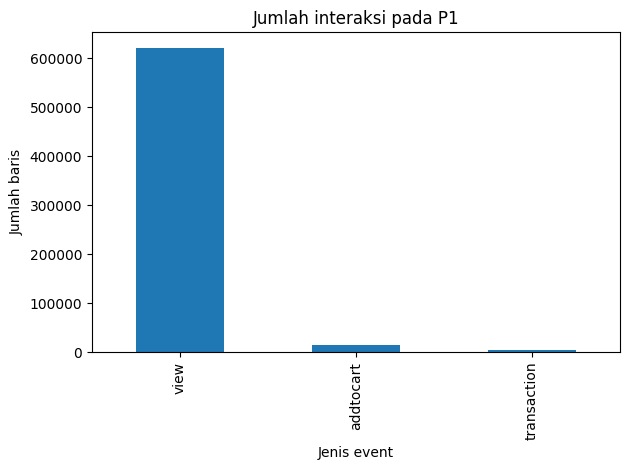

In [3]:
p1 = pd.read_csv(P1_FILE)
p2 = pd.read_csv(P2_FILE)
print("P1:", p1.shape, "| P2:", p2.shape)
display(pd.DataFrame({
    "periode": ["P1 training", "P2 testing"],
    "mulai": [START_P1, START_P2],
    "akhir_eksklusif": [END_P1, END_P2],
    "jumlah_baris": [len(p1), len(p2)],
    "jumlah_visitor": [p1.visitorid.nunique(), p2.visitorid.nunique()],
    "jumlah_item": [p1.itemid.nunique(), p2.itemid.nunique()],
}).set_index("periode"))
display(p1["event"].value_counts().rename("jumlah").to_frame())
ax = p1["event"].value_counts().reindex(["view", "addtocart", "transaction"]).plot(kind="bar", title="Jumlah interaksi pada P1")
ax.set_xlabel("Jenis event"); ax.set_ylabel("Jumlah baris"); plt.tight_layout(); plt.show()

### Query Cypher untuk komposisi simpul dan relasi

Setelah data diimpor ke Neo4j, query berikut menghitung tipe simpul. `labels(n)` mengambil label node dan `count(n)` menghitung banyak node per label.

## 4. Bangun VSM User dari P1

In [5]:
# Setiap baris = visitor; setiap kolom = item; nilai = jumlah interaksi visitor-item.
# Untuk membatasi memori, gunakan visitor/item yang cukup aktif jika laptop memiliki RAM terbatas.
train = p1.dropna(subset=["visitorid", "itemid"]).copy()
train["visitorid"] = train["visitorid"].astype("int64")
train["itemid"] = train["itemid"].astype("int64")
user_item_counts = train.groupby(["visitorid", "itemid"]).size().rename("weight").reset_index()
users = pd.Index(user_item_counts["visitorid"].unique(), name="visitorid")
items = pd.Index(user_item_counts["itemid"].unique(), name="itemid")
user_index = {v:i for i,v in enumerate(users)}
item_index = {v:i for i,v in enumerate(items)}
X_user_item = csr_matrix(
    (user_item_counts["weight"].to_numpy(),
     (user_item_counts["visitorid"].map(user_index), user_item_counts["itemid"].map(item_index))),
    shape=(len(users), len(items))
)
print("VSM User × Item shape:", X_user_item.shape)
print("Jumlah nilai non-zero:", X_user_item.nnz)
print("Kerapatan matriks:", round(X_user_item.nnz / (X_user_item.shape[0] * X_user_item.shape[1]), 8))

VSM User × Item shape: (334870, 120577)
Jumlah nilai non-zero: 499198
Kerapatan matriks: 1.236e-05


## 5. VSM Item dan perbandingan proyeksi

In [6]:
X_item_user = X_user_item.T.tocsr()
print("VSM Item × User shape:", X_item_user.shape)
print("Jumlah nilai non-zero:", X_item_user.nnz)
print("Kerapatan matriks:", round(X_item_user.nnz / (X_item_user.shape[0] * X_item_user.shape[1]), 8))

# Ringkasan proyeksi: proyeksi user berukuran jumlah user × jumlah user;
# proyeksi item berukuran jumlah item × jumlah item. Hindari membuat matriks similarity dense besar.
n_users, n_items = X_user_item.shape
print(f"Proyeksi User potensial: {n_users:,} × {n_users:,}")
print(f"Proyeksi Item potensial: {n_items:,} × {n_items:,}")

VSM Item × User shape: (120577, 334870)
Jumlah nilai non-zero: 499198
Kerapatan matriks: 1.236e-05
Proyeksi User potensial: 334,870 × 334,870
Proyeksi Item potensial: 120,577 × 120,577


**Pembahasan:** VSM User × Item menyatakan preferensi setiap visitor atas item, sedangkan VSM Item × User menyatakan audiens setiap item. Pada dataset interaksi ritel, jumlah visitor biasanya jauh lebih banyak daripada jumlah item aktif atau sebaliknya tergantung filter; pilihan proyeksi yang lebih efisien ditentukan dari dimensi aktual di atas dan kebutuhan rekomendasi. Untuk rekomendasi personal, proyeksi user memudahkan mencari visitor serupa; implementasi di bawah memakai matriks sparse dan KNN agar tidak membentuk matriks similarity dense berukuran sangat besar.

## 6. Similarity user dan 5 tetangga teratas

In [ ]:

user_activity = np.asarray(X_user_item.getnnz(axis=1)).ravel()
eligible = np.flatnonzero(user_activity >= 2)
if len(eligible) < 2:
    raise ValueError("Data tidak cukup untuk menghitung similarity user.")
anchor_row = int(eligible[0])
anchor_user = int(users[anchor_row])
# Cosine similarity dihitung ke semua user dengan sparse matrix.
anchor_vec = X_user_item[anchor_row]
sims = cosine_similarity(anchor_vec, X_user_item, dense_output=True).ravel()
sims[anchor_row] = -1
top_idx = np.argsort(sims)[::-1][:5]
top5_similarity = pd.DataFrame({
    "visitorid": users.to_numpy()[top_idx],
    "cosine_similarity": sims[top_idx]
})
print("User acuan:", anchor_user)
display(top5_similarity)

User acuan: 23


,visitorid,cosine_similarity
0,333526,0.894427
1,1267473,0.894427
2,1183391,0.894427
3,641058,0.894427
4,870194,0.894427


### Query Cypher untuk menampilkan 5 similarity tertinggi



## 7.

In [ ]:


NEO4J_URI = "neo4j://localhost:7687"
NEO4J_AUTH = ("neo4j", "grafsainsdata")  # sesuaikan jika password berbeda
DATABASE = "neo4j"

def save_similarity(driver, anchor_id, neighbor_rows):
    query = '''
    MATCH (a:Visitor {visitorId: $anchor_id})
    MATCH (b:Visitor {visitorId: $neighbor_id})
    MERGE (a)-[r:SIMILAR_TO]->(b)
    SET r.score = $score
    '''
    with driver.session(database=DATABASE) as session:
        for row in neighbor_rows:
            session.run(query, anchor_id=int(anchor_id),
                        neighbor_id=int(row.visitorid), score=float(row.cosine_similarity)).consume()



## 8. KNN: user acak yang dapat direproduksi dan 3 rekomendasi

In [ ]:

RANDOM_STATE = 42
test_user_ids = set(p2["visitorid"].dropna().astype("int64").unique())
candidate_rows = np.array([
    i for i, visitor_id in enumerate(users)
    if user_activity[i] >= 3 and int(visitor_id) in test_user_ids
], dtype=int)
if len(candidate_rows) == 0:
    raise ValueError("Tidak ada user yang memenuhi syarat untuk evaluasi P2.")
target_row = int(np.random.default_rng(RANDOM_STATE).choice(candidate_rows))
target_user = int(users[target_row])
print("Random state:", RANDOM_STATE, "| target visitor:", target_user)
print("Item unik pada P1:", int(user_activity[target_row]))

# KNN k=5 menggunakan cosine similarity pada VSM User × Item (sparse).
similarities_to_target = cosine_similarity(X_user_item[target_row], X_user_item).ravel()
similarities_to_target[target_row] = -1
neighbor_rows = np.argsort(similarities_to_target)[::-1][:5]
neighbor_ids = users.to_numpy()[neighbor_rows]
print("5 tetangga terdekat:", neighbor_ids.tolist())

target_seen = set(user_item_counts.loc[user_item_counts.visitorid == target_user, "itemid"])
neighbor_events = user_item_counts[user_item_counts.visitorid.isin(neighbor_ids)]
scores = (neighbor_events[~neighbor_events["itemid"].isin(target_seen)]
          .groupby("itemid")["weight"].sum().sort_values(ascending=False))
recommendations = scores.head(3)
recommended_items = recommendations.index.astype("int64").tolist()
display(pd.DataFrame({"itemid": recommended_items, "score": recommendations.values}))


Random state:

 42 | target visitor: 121151
Item unik pada P1: 7
5 tetangga terdekat: [702, 469538, 469542, 469547, 469561]


,itemid,score
0,111675,2
1,46478,1
2,5411,1


## 9. Evaluasi Hit@5 dan NDCG@5 menggunakan P2

In [11]:
# Ground truth: item yang sama visitor interaksikan pada periode P2.
test = p2.dropna(subset=["visitorid", "itemid"]).copy()
test["visitorid"] = test["visitorid"].astype("int64")
test["itemid"] = test["itemid"].astype("int64")
relevant = set(test.loc[test.visitorid == target_user, "itemid"].unique())

top5_recs = scores.head(5).index.astype("int64").tolist()
hits = [1 if item in relevant else 0 for item in top5_recs]
hit_at_5 = float(any(hits))
dcg = sum(rel / np.log2(rank + 2) for rank, rel in enumerate(hits))
idcg = sum(1 / np.log2(rank + 2) for rank in range(min(len(relevant), 5)))
ndcg_at_5 = float(dcg / idcg) if idcg > 0 else 0.0
print("Target visitor:", target_user)
print("Jumlah item relevan pada P2:", len(relevant))
print("Top-5 rekomendasi:", top5_recs)
print("Relevansi top-5:", hits)
print(f"Hit@5 = {hit_at_5:.4f}")
print(f"NDCG@5 = {ndcg_at_5:.4f}")


Target visitor: 121151
Jumlah item relevan pada P2: 5
Top-5 rekomendasi: [111675, 46478, 5411, 71242, 144014]
Relevansi top-5: [0, 0, 0, 0, 0]
Hit@5 = 0.0000
NDCG@5 = 0.0000


## 10. Simpan hasil analisis dan kesimpulan

In [12]:
summary = pd.DataFrame([{
    "p1_start_inclusive": START_P1,
    "p1_end_exclusive": END_P1,
    "p1_rows": len(p1),
    "p2_start_inclusive": START_P2,
    "p2_end_exclusive": END_P2,
    "p2_rows": len(p2),
    "target_visitor_seed_42": target_user,
    "top5_items": str(top5_recs),
    "Hit@5": hit_at_5,
    "NDCG@5": ndcg_at_5,
}])
summary.to_csv("hasil_evaluasi.csv", index=False)
display(summary)

,p1_start_inclusive,p1_end_exclusive,p1_rows,p2_start_inclusive,p2_end_exclusive,p2_rows,target_visitor_seed_42,top5_items,Hit@5,NDCG@5
0,2015-05-18,2015-06-18,642023,2015-08-18,2015-09-18,560324,121151,"[111675, 46478, 5411, 71242, 144014]",0.0,0.0


### Kesimpulan
1. Data RetailRocket dibagi menjadi data training (P1) dari 18 Mei sampai sebelum 18 Juni 2015 dan data testing (P2) dari 18 Agustus sampai sebelum 18 September 2015. Pembagian dilakukan berdasarkan timestamp sehingga kedua periode tidak tumpang tindih.
2. Vector Space Model (VSM) digunakan untuk merepresentasikan interaksi user dan item. Representasi User × Item digunakan untuk menghitung kemiripan antaruser, sedangkan Item × User menggambarkan interaksi dari sisi item.
3. Cosine similarity digunakan untuk mengukur kemiripan antaruser berdasarkan pola interaksi pada data training. Hasil perhitungan kemiripan digunakan untuk menentukan tetangga terdekat yang dapat mendukung proses rekomendasi.
4. K-Nearest Neighbors (KNN) digunakan untuk menghasilkan lima rekomendasi item bagi target user 121151. Pengaturan seed NumPy sebesar 42 digunakan agar pemilihan target user dapat direproduksi.
5. Evaluasi menggunakan data P2 sebagai ground truth menghasilkan Hit@5 sebesar 0,0000 dan NDCG@5 sebesar 0,0000. Pada pengujian target user ini, tidak ada item rekomendasi yang cocok dengan item relevan pada periode pengujian. Hasil tersebut menunjukkan bahwa rekomendasi untuk target user yang diuji masih perlu ditingkatkan.

Secara keseluruhan, alur pengolahan data, VSM, perhitungan kemiripan, rekomendasi KNN, dan evaluasi telah dilakukan. Pengujian terhadap lebih banyak user diperlukan untuk mendapatkan gambaran kinerja sistem yang lebih menyeluruh.
